# 5. Exercise: mixing in a quiet and in a sheared ocean

During PIRATA FR-36 (March 2026), turbulence was measured at 24 stations along 10°W. We compare two of them:

- **9.5°S (station 26)**: away from the equator, where currents are weak;
- **0°N (station 7)**: on the equator, where the Equatorial Undercurrent flows below the surface (part 3).

**Part I. Understand the data**
1. Look at the two profiles: temperature, stratification, oxygen, current and turbulence.
2. Check that we can trust $\varepsilon$.

**Part II. Interpret**

3. Find why turbulence is stronger just below the mixed layer at the equator.
4. Compute the fluxes of heat and oxygen below the mixed layer, and compare them with published values.

**How it works.** Most cells are ready: just run them. The cells marked **✏️ Your turn** are yours: complete with your code. The solution is hidden just below. The answers to the questions are in the dropdowns: try first!

# Part I. Understand the data

## Step 1. Two profiles

We first look at the two stations: temperature, stratification, oxygen, current and turbulence. Open the file of VMP profiles and look at what it contains.

In [95]:
# Load the libraries and open the file of VMP profiles
import numpy as np
import xarray as xr
import gsw
import matplotlib.pyplot as plt

prof = xr.open_dataset("data/fr36_profiles.nc")
prof

<xarray.Dataset> Size: 122kB
Dimensions:  (station: 24, pres: 125)
Coordinates:
  * pres     (pres) float64 1kB 1.0 3.0 5.0 7.0 9.0 ... 243.0 245.0 247.0 249.0
  * station  (station) <U6 576B 'stat4' 'stat5' 'stat6' ... 'stat26' 'stat27'
Data variables:
    temp     (station, pres) float64 24kB ...
    sal      (station, pres) float64 24kB ...
    o2       (station, pres) float64 24kB ...
    chla     (station, pres) float64 24kB ...
    eps      (station, pres) float64 24kB ...
    lat      (station) float64 192B ...
    lon      (station) float64 192B ...
    time     (station) datetime64[ns] 192B ...
    mld      (station) float64 192B ...
Attributes:
    title:           PIRATA FR-36, VMP-250 profiles along 10W, March 2026 (co...
    eps_processing:  ATOMIX levels, toolbox of C. Vic; 2-dbar medians of EPSI...

In [133]:
# For our two stations, compute the potential density and the stratification N2 from temperature and salinity
pres = prof.pres.values
stations = {"stat26": "tab:blue", "stat7": "tab:red"}     # 9.5°S, 0°N

col = {}
for s in stations:
    p = prof.sel(station=s)
    SA = gsw.SA_from_SP(p.sal.values, pres, float(p.lon), float(p.lat))
    CT = gsw.CT_from_t(SA, p.temp.values, pres)
    n2, p_mid = gsw.Nsquared(SA, CT, pres, lat=float(p.lat))
    col[s] = {"temp": p.temp.values, "o2": p.o2.values, "sigma": gsw.sigma0(SA, CT),
              "N2": np.interp(pres, p_mid, n2), "lat": float(p.lat)}

**✏️ Your turn.** The base of the mixed layer (MLD) is the first depth where the density exceeds the density of the shallowest measurement by 0.03 kg m⁻³ (de Boyer Montégut et al., 2004). Compute the MLD at each station.

In [143]:
# MLD: first depth where the density exceeds the shallowest density by 0.03 kg m-3
for s in stations:
    sigma = col[s]["sigma"]
    ref = sigma[np.isfinite(sigma)][0]              # density of the shallowest measurement
    col[s]["mld"] = pres[np.argmax(sigma > ref + 0.125)]
    print(col[s]["lat"], "°N: MLD =", col[s]["mld"], "m")

-9.5 °N: MLD = 49.0 m
0.0 °N: MLD = 17.0 m


The currents were measured by a lowered ADCP (L-ADCP), fixed on the CTD frame, during the CTD cast made at the same station just before the VMP. They are averaged over 16 m. Open the file and look at what it contains.

In [140]:
# Open the file of currents (L-ADCP) and stratification (CTD) at the two stations
ss = xr.open_dataset("data/shear_strat_stat7_stat26.nc").drop_vars("Ri")
ss

<xarray.Dataset> Size: 1kB
Dimensions:    (station: 2, depth: 18, depth_mid: 17)
Coordinates:
  * station    (station) <U6 48B 'stat7' 'stat26'
  * depth      (depth) float64 144B 16.0 32.0 48.0 64.0 ... 256.0 272.0 288.0
  * depth_mid  (depth_mid) float64 136B 24.0 40.0 56.0 ... 248.0 264.0 280.0
Data variables:
    u          (station, depth) float32 144B ...
    v          (station, depth) float32 144B ...
    temp       (station, depth) float32 144B ...
    sal        (station, depth) float32 144B ...
    N2         (station, depth_mid) float64 272B ...
    S2         (station, depth_mid) float64 272B ...
    lat        (station) float64 16B ...
    lon        (station) float64 16B ...
Attributes:
    title:    PIRATA FR-36, L-ADCP velocity and CTD stratification on the L-A...
    note:     T, S averaged in L-ADCP bins; N2 (TEOS-10) and S2 between the s...

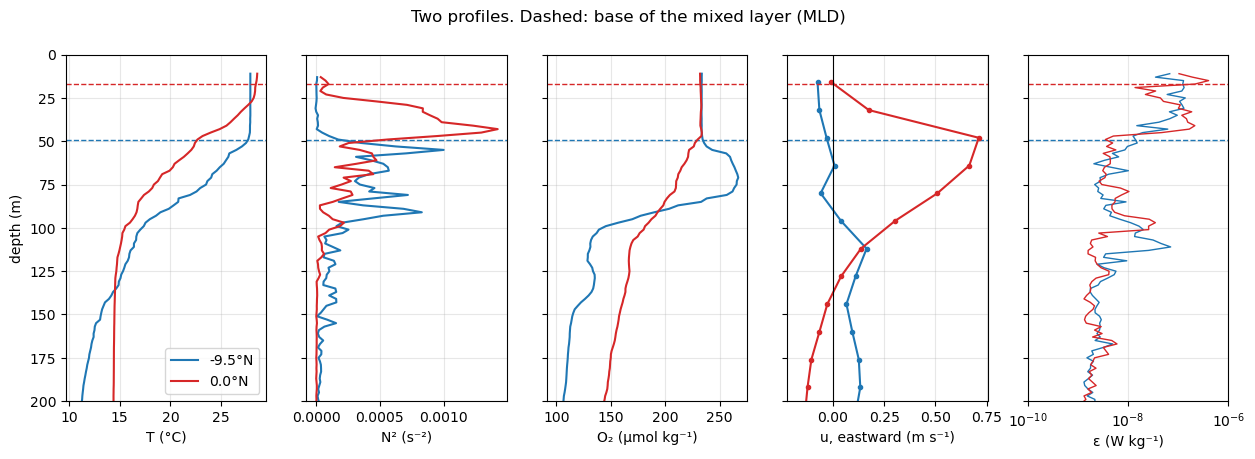

In [145]:
# Plot temperature, stratification, oxygen, eastward current and eps at the two stations
fig, axs = plt.subplots(1, 5, figsize=(15, 4.5), sharey=True)
for s, c in stations.items():
    lab = f"{col[s]['lat']:.1f}°N"
    axs[0].plot(col[s]["temp"], pres, color=c, label=lab)
    axs[1].plot(col[s]["N2"], pres, color=c)
    axs[2].plot(col[s]["o2"], pres, color=c)
    axs[3].plot(ss.u.sel(station=s), ss.depth, "o-", ms=3, color=c)
    axs[4].semilogx(prof.eps.sel(station=s), pres, color=c, lw=1)
    for ax in axs:
        ax.axhline(col[s]["mld"], color=c, ls="--", lw=1)
axs[3].axvline(0, color="k", lw=0.8)
labels = ["T (°C)", "N² (s⁻²)", "O₂ (µmol kg⁻¹)", "u, eastward (m s⁻¹)", "ε (W kg⁻¹)"]
for ax, label in zip(axs, labels):
    ax.set_xlabel(label); ax.grid(alpha=0.3)
axs[4].set_xlim(1e-10, 1e-6)
axs[0].set_ylim(200, 0); axs[0].set_ylabel("depth (m)"); axs[0].legend()
fig.suptitle("Two profiles. Dashed: base of the mixed layer (MLD)");

::::{note} Questions
**1.1** Describe the two profiles: mixed layer, stratification, oxygen and current. What differs between the two stations?

**1.2** Describe where $\varepsilon$ is high and where it is low, with reference to the base of the mixed layer. Where does the equator differ from 9.5°S?

:::{dropdown} Answers
**1.1**
- **9.5°S**: a thick mixed layer (49 m), a strong stratification just below it, a sharp oxycline near 87 m, and weak currents.
- **Equator**: a thin mixed layer (17 m), a stronger stratification below it, oxygen decreasing slowly with depth, and a strong eastward current below the surface (0.7 m s⁻¹ near 48 m): the Equatorial Undercurrent.

**1.2**
- In the mixed layer, $\varepsilon$ is high at both stations: the wind stirs the surface.
- Just below the mixed layer, $\varepsilon$ drops quickly at 9.5°S, but stays high over a few tens of meters at the equator, in the layer where the undercurrent flows.
- Deeper, the two stations are similar. Part II quantifies this difference and looks for its cause.
:::
::::

## Step 2. Can we trust ε?

For each station, a second file gives the details of the turbulence measurement. The descent is cut into **segments** of a few meters. For each segment, the shear spectrum of each probe is integrated to give $\varepsilon$ (part 4): $\varepsilon_1$ and $\varepsilon_2$ for the two probes, and a final $\varepsilon$ after the quality checks.

In [101]:
# Open the segment files of the two stations and look at what they contain
seg = {s: xr.open_dataset(f"data/fr36_segments_{s}.nc") for s in stations}
seg["stat7"]

<xarray.Dataset> Size: 1MB
Dimensions:        (probe: 2, segment: 166, k_index: 257)
Coordinates:
  * probe          (probe) int64 16B 1 2
Dimensions without coordinates: segment, k_index
Data variables:
    seg_eps_probe  (probe, segment) float64 3kB ...
    seg_eps_final  (segment) float64 1kB ...
    seg_pres       (segment) float64 1kB ...
    seg_k          (segment, k_index) float64 341kB ...
    seg_spec       (probe, segment, k_index) float64 683kB ...
Attributes:
    check_station:  stat7
    station:        stat7
    lat:            0.0

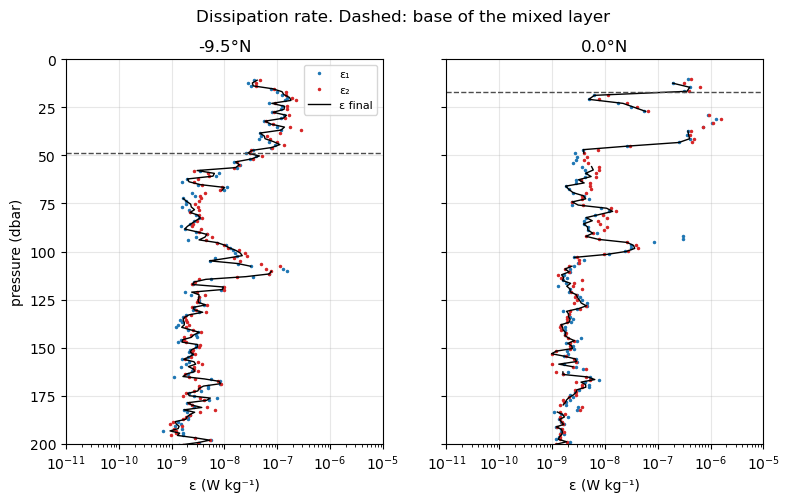

In [149]:
# Plot eps of each probe and the final eps along the descent, at the two stations
fig, axs = plt.subplots(1, 2, figsize=(9, 5), sharey=True, sharex=True)
for ax, s in zip(axs, stations):
    d = seg[s]
    o = np.argsort(d.seg_pres.values)
    ax.semilogx(d.seg_eps_probe.sel(probe=1), d.seg_pres, ".", ms=3, color="tab:blue", label="ε₁")
    ax.semilogx(d.seg_eps_probe.sel(probe=2), d.seg_pres, ".", ms=3, color="tab:red", label="ε₂")
    ax.semilogx(d.seg_eps_final.values[o], d.seg_pres.values[o], "k-", lw=1, label="ε final")
    ax.axhline(col[s]["mld"], color="0.3", ls="--", lw=1)
    ax.set_title(f"{col[s]['lat']:.1f}°N"); ax.set_xlabel("ε (W kg⁻¹)"); ax.grid(alpha=0.3)
axs[0].set_xlim(1e-11, 1e-5); axs[0].set_ylim(200, 0); axs[0].set_ylabel("pressure (dbar)"); axs[0].legend(fontsize=8)
fig.suptitle("Dissipation rate. Dashed: base of the mixed layer");

::::{note} Questions
**2.1** Along the profile, do $\varepsilon_1$ and $\varepsilon_2$ (blue and red dots) follow each other?

The black line is the final $\varepsilon$. Where a segment fails the quality checks, it has no final value, and the black line has a gap. Where are these gaps?

:::{dropdown} Answers
- At both stations, the two probes follow each other closely along the whole profile, from $10^{-9}$ to $10^{-6}$ W kg⁻¹: they see the same turbulence.
- The gaps in the black line are few. Most of them are at the equator near 30–40 dbar, where turbulence is the strongest. We see why in 2.2 and 2.4.
:::
::::

**✏️ Your turn.** On the equatorial profile, choose the pressure of one segment with a high $\varepsilon$ and one with a low $\varepsilon$.

In [104]:
# Pressures (dbar) of one segment with high eps and one with low eps, at the equator
p_high, p_low = 40, 130

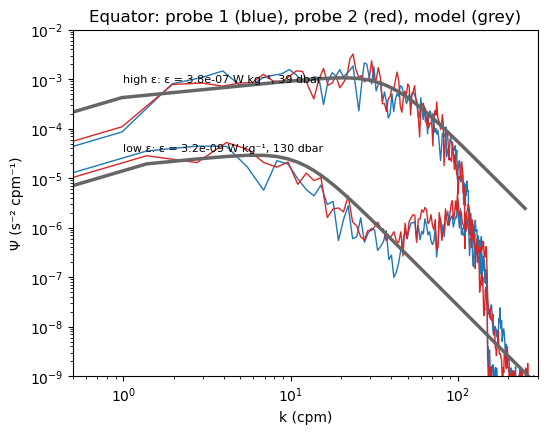

In [105]:
# Plot the measured spectra of the two probes and the model spectrum, for the two chosen segments
d = seg["stat7"]
fig, ax = plt.subplots(figsize=(6, 4.5))
for p0, lab in [(p_high, "high ε"), (p_low, "low ε")]:
    i = int(np.argmin(np.abs(d.seg_pres.values - p0)))       # closest segment
    k, e = d.seg_k.values[i], float(d.seg_eps_final[i])
    ax.loglog(k, d.seg_spec.sel(probe=1).values[i], color="tab:blue", lw=1)
    ax.loglog(k, d.seg_spec.sel(probe=2).values[i], color="tab:red", lw=1)
    ax.loglog(k, model_spectrum(k, e), color="0.4", lw=2.5)
    ax.text(1, 2 * model_spectrum(1.0, e), f"{lab}: ε = {e:.1e} W kg⁻¹, {d.seg_pres.values[i]:.0f} dbar", fontsize=8)
ax.set_xlim(0.5, 300); ax.set_ylim(1e-9, 1e-2)
ax.set_xlabel("k (cpm)"); ax.set_ylabel("Ψ (s⁻² cpm⁻¹)")
ax.set_title("Equator: probe 1 (blue), probe 2 (red), model (grey)");

::::{note} Questions
**2.2** How does the spectrum change from the low-$\varepsilon$ to the high-$\varepsilon$ segment? What does it tell about the size of the smallest eddies ($\eta$, part 2)? Over which range of wavenumbers do the measured spectra follow the model, and what happens beyond?

:::{dropdown} Answers
- With a higher $\varepsilon$, the spectrum is higher and extends to larger wavenumbers, that is, to smaller eddies: $\eta = (\nu^3/\varepsilon)^{1/4}$ is about 1.3 mm for the high-$\varepsilon$ segment ($3.8 \times 10^{-7}$ W kg⁻¹), and about 4 mm for the low-$\varepsilon$ segment ($3.2 \times 10^{-9}$ W kg⁻¹).
- $\eta$ is the scale where viscosity wins, but most of the dissipation happens in eddies 10 to 50 times larger, of a few centimetres: the spectrum peaks near 20 cpm (about 5 cm) for the high-$\varepsilon$ segment, and near 6 cpm for the low-$\varepsilon$ one.
- The high-$\varepsilon$ spectra follow the model up to about 100 cpm, which holds about 96 % of $\varepsilon$. Beyond, they fall below it: the probe (about 1 cm) no longer resolves the smallest eddies. The model adds this small missing part.
- The low-$\varepsilon$ spectra follow the model only up to about 15–20 cpm. Between about 30 and 100 cpm, they rise above it: this is noise and vibrations of the instrument, not turbulence. The processing stops the integral before (part 4), and the model adds the missing part.
:::
::::

**✏️ Your turn.** Two probes a few centimetres apart see the same turbulence, so their $\varepsilon$ should agree within a factor of 2, that is $1/2 < \varepsilon_2/\varepsilon_1 < 2$.

In [150]:
# Fraction of segments where the two probes agree within a factor of 2
for s in stations:
    e1 = seg[s].seg_eps_probe.sel(probe=1).values      # eps of probe 1
    e2 = seg[s].seg_eps_probe.sel(probe=2).values      # eps of probe 2
    ratio = e2 / e1
    good = (ratio > 0.5) & (ratio < 2)                 # True where 1/2 < ratio < 2
    fraction = np.mean(good)
    print(col[s]["lat"], "°N:", round(100 * fraction), "% of the segments agree")

-9.5 °N: 89 % of the segments agree
0.0 °N: 82 % of the segments agree


**Quality checks (reminder, part 4).** In the processing (toolbox of Vic et al., following ATOMIX; Lueck et al., 2024), each estimate of $\varepsilon$ is checked:

- **the shape of the spectrum**: the measured spectrum must follow the model spectrum (part 4);
- **the resolved part**: most of the spectrum must be measured above the noise and within the range the probe resolves;
- **the instrument**: the VMP must fall steadily, without strong tilt or vibrations.

The final $\varepsilon$ is the mean of the two probes when both pass the checks, the value of the only probe that passes, or nothing when neither passes.

-9.5°N: 222 kept (23 from one probe only), 3 rejected
0.0°N: 153 kept (30 from one probe only), 13 rejected


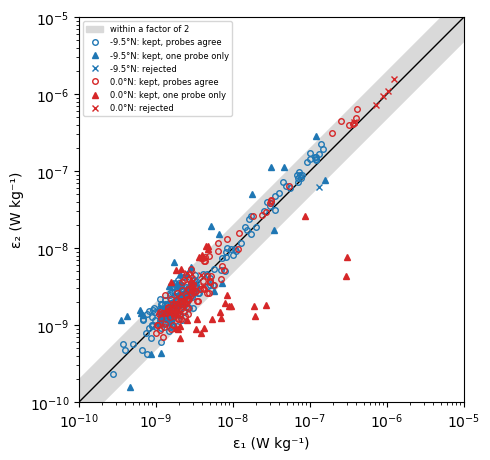

In [108]:
# Plot eps of probe 2 against eps of probe 1, and show what the quality checks did with each segment
fig, ax = plt.subplots(figsize=(5, 5))
x = np.logspace(-10, -5, 50)
ax.fill_between(x, x / 2, 2 * x, color="0.85", label="within a factor of 2")
ax.plot(x, x, "k-", lw=1)
for s, c in stations.items():
    e1, e2 = seg[s].seg_eps_probe.sel(probe=1).values, seg[s].seg_eps_probe.sel(probe=2).values
    kept = np.isfinite(seg[s].seg_eps_final.values)
    agree = (e2 / e1 > 0.5) & (e2 / e1 < 2)
    lat = f"{col[s]['lat']:.1f}°N"
    ax.loglog(e1[kept & agree], e2[kept & agree], "o", ms=4, mfc="none", color=c, label=f"{lat}: kept, probes agree")
    ax.loglog(e1[kept & ~agree], e2[kept & ~agree], "^", ms=5, color=c, label=f"{lat}: kept, one probe only")
    ax.loglog(e1[~kept], e2[~kept], "x", ms=5, color=c, label=f"{lat}: rejected")
    print(f"{lat}: {kept.sum()} kept ({(kept & ~agree).sum()} from one probe only), {(~kept).sum()} rejected")
ax.set_xlim(1e-10, 1e-5); ax.set_ylim(1e-10, 1e-5); ax.set_aspect("equal")
ax.set_xlabel("ε₁ (W kg⁻¹)"); ax.set_ylabel("ε₂ (W kg⁻¹)"); ax.legend(fontsize=6, loc="upper left");

::::{note} Questions
**2.3** Do the two probes measure the same turbulence? For which values of $\varepsilon$ would you be less confident about the result?

**2.4** What did the quality checks do with the segments where the two probes disagree? And with the strongest $\varepsilon$ at the equator?

:::{dropdown} Answers
**2.3**
- Most segments fall within a factor of 2 (about 90 % at 9.5°S and 80 % at the equator): the two probes, a few centimeters apart, see the same turbulence.
- The scatter is largest at low $\varepsilon$ (around $10^{-9}$ W kg⁻¹), where the signal gets closer to the noise of the instrument (about $10^{-10}$ W kg⁻¹, part 4).

**2.4**
- When the two probes disagree, the segment is often still kept (triangles): one probe failed the checks, and the final $\varepsilon$ comes from the other one only (part 4).
- At the equator, the strongest segments ($\varepsilon$ above about $7 \times 10^{-7}$ W kg⁻¹) are rejected (crosses), although the two probes agree. Here the problem is not a disagreement: turbulence is so strong that the spectrum is no longer resolved by the probe, as seen in 2.2. This is the limit of very high $\varepsilon$ (part 4).
- Two probes and quality checks are therefore complementary: agreement between the probes is necessary, but not sufficient.
:::
::::

# Part II. Interpret

## Step 3. Turbulence just below the mixed layer

**Why the base of the mixed layer?** The mixed layer is in contact with the atmosphere; below its base, the water is stratified and isolated from the surface. Everything exchanged between the surface and the ocean interior must cross this boundary: the heat that cools the surface, the nutrients that come up to the light, the oxygen that goes down (part 3). Just below the mixed layer, only turbulence can carry these properties across the stratification: this is where we look at $\varepsilon$.

In step 1, the stratification just below the mixed layer was the same at both stations, but $\varepsilon$ was much larger at the equator. **Why?**

To answer, we compare the **shear** of the current, $S^2 = (\partial u/\partial z)^2 + (\partial v/\partial z)^2$, which feeds turbulence, with the stratification $N^2$, which resists it. Both are computed on the same 16-m grid (file `ss`). Because of this 16-m grid, we look at the first **40 m** below the mixed layer: it holds three levels of the grid at each station.

The ratio of stratification to shear is the **gradient Richardson number**:

$$
Ri = \frac{N^2}{S^2}
$$

When $Ri < 1/4$, the shear can overcome the stratification and the flow can become unstable (Miles, 1961; Howard, 1961). Compute $Ri$ at the two stations from `ss.N2` and `ss.S2`.

In [153]:
# Average eps of the VMP on the 16-m grid of S2 and N2
zm = ss.depth_mid.values                     # depths of the 16-m grid where S2, N2 and Ri are computed
eps16 = {}
for s in stations:
    eps16[s] = np.array([np.nanmean(prof.eps.sel(station=s).values[(pres >= z - 8) & (pres < z + 8)]) for z in zm])

/var/folders/hx/5w0827ns1014hp25tcdjlpj80000gp/T/ipykernel_82637/2668190740.py:5: RuntimeWarning: Mean of empty slice
  eps16[s] = np.array([np.nanmean(prof.eps.sel(station=s).values[(pres >= z - 8) & (pres < z + 8)]) for z in zm])
/var/folders/hx/5w0827ns1014hp25tcdjlpj80000gp/T/ipykernel_82637/2668190740.py:5: RuntimeWarning: Mean of empty slice
  eps16[s] = np.array([np.nanmean(prof.eps.sel(station=s).values[(pres >= z - 8) & (pres < z + 8)]) for z in zm])


**✏️ Your turn.** Compute Ri`and select the first 40 m below the mixed layer

In [155]:
# Gradient Richardson number, and selection of the first 40 m below the mixed layer
Ri = ss.N2 / ss.S2                            # Ri = N2 / S2
layer = {}
for s in stations:
    mld = col[s]["mld"]
    layer[s] = (zm > mld) & (zm <= mld + 40)  # True where mld < zm <= mld + 40

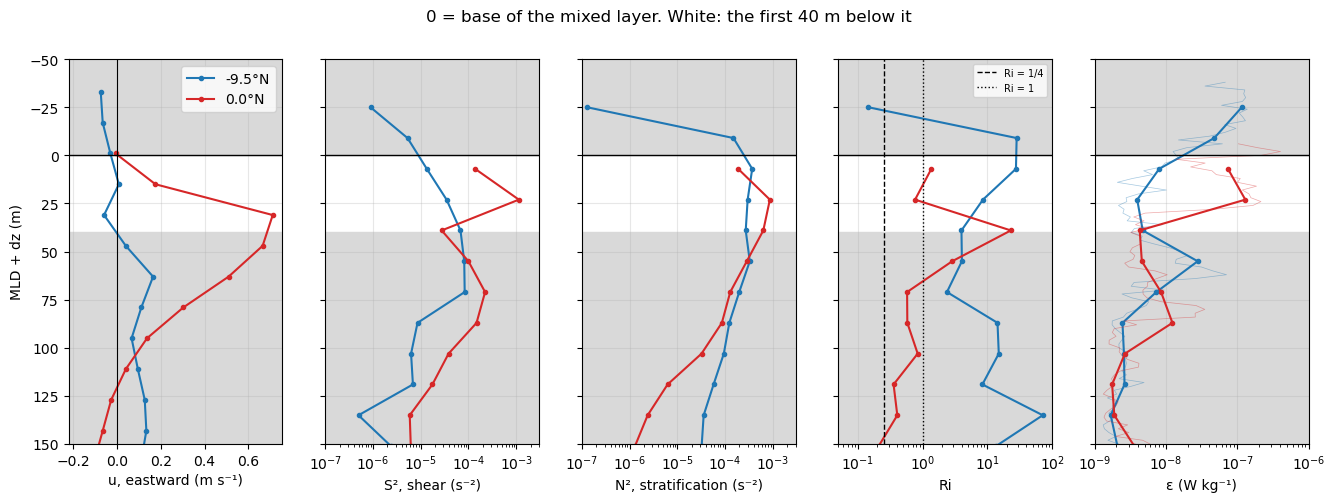

In [152]:
# Current, shear, stratification, Ri and eps against the depth below the mixed layer (MLD + dz), as in Hummels et al. (2013)
fig, axs = plt.subplots(1, 5, figsize=(16, 5), sharey=True)
for s, c in stations.items():
    lab = f"{col[s]['lat']:.1f}°N"
    dz_u = ss.depth.values - col[s]["mld"]          # depth below the mixed layer, for u
    dz_m = zm - col[s]["mld"]                       # depth below the mixed layer, for S2, N2, Ri and eps
    axs[0].plot(ss.u.sel(station=s), dz_u, "o-", ms=3, color=c, label=lab)
    axs[1].semilogx(ss.S2.sel(station=s), dz_m, "o-", ms=3, color=c)
    axs[2].semilogx(ss.N2.sel(station=s), dz_m, "o-", ms=3, color=c)
    axs[3].semilogx(Ri.sel(station=s), dz_m, "o-", ms=3, color=c)
    axs[4].semilogx(prof.eps.sel(station=s), pres - col[s]["mld"], color=c, lw=0.5, alpha=0.4)
    axs[4].semilogx(eps16[s], dz_m, "o-", ms=3, color=c)
axs[0].axvline(0, color="k", lw=0.8)
axs[3].axvline(0.25, color="k", ls="--", lw=1, label="Ri = 1/4")
axs[3].axvline(1, color="k", ls=":", lw=1, label="Ri = 1")
labels = ["u, eastward (m s⁻¹)", "S², shear (s⁻²)", "N², stratification (s⁻²)", "Ri", "ε (W kg⁻¹)"]
for ax, label in zip(axs, labels):
    ax.axhspan(-50, 0, color="0.85")            # mixed layer
    ax.axhspan(40, 150, color="0.85")           # deeper than 40 m below the mixed layer
    ax.axhline(0, color="k", lw=1)
    ax.set_xlabel(label); ax.grid(alpha=0.3)
axs[1].set_xlim(1e-7, 3e-3); axs[2].set_xlim(1e-7, 3e-3); axs[3].set_xlim(0.05, 100); axs[4].set_xlim(1e-9, 1e-6)
axs[0].set_ylim(150, -50); axs[0].set_ylabel("MLD + dz (m)")
axs[0].legend(); axs[3].legend(fontsize=7)
fig.suptitle("0 = base of the mixed layer. White: the first 40 m below it");

**✏️ Your turn.** On the 16-m grid, compute the median of $\varepsilon$, $S^2$, $N^2$ and $Ri$ in two layers at each station:

- **below**: the first 40 m below the mixed layer;
- **deeper**: from 40 to 150 m below the mixed layer.

In [156]:
# Median of eps, S2, N2 and Ri on the 16-m grid, 0-40 m and 40-150 m below the mixed layer
for s in stations:
    mld = col[s]["mld"]
    eps = eps16[s]
    S2 = ss.S2.sel(station=s).values
    N2 = ss.N2.sel(station=s).values
    R = Ri.sel(station=s).values

    below = (zm > mld) & (zm <= mld + 40)           # 0 to 40 m below the mixed layer
    deeper = (zm > mld + 40) & (zm <= mld + 150)    # 40 to 150 m below the mixed layer

    print(col[s]["lat"], "°N")
    print("  below : eps =", f"{np.median(eps[below]):.1e}")
    print("          S2  =", f"{np.median(S2[below]):.1e}")
    print("          N2  =", f"{np.median(N2[below]):.1e}")
    print("          Ri  =", f"{np.median(R[below]):.1e}")
    print("  deeper: eps =", f"{np.median(eps[deeper]):.1e}")
    print("          S2  =", f"{np.median(S2[deeper]):.1e}")
    print("          N2  =", f"{np.median(N2[deeper]):.1e}")
    print("          Ri  =", f"{np.median(R[deeper]):.1e}")

-9.5 °N
  below : eps = 4.7e-09
          S2  = 3.5e-05
          N2  = 3.0e-04
          Ri  = 8.6e+00
  deeper: eps = 2.6e-09
          S2  = 7.7e-06
          N2  = 1.1e-04
          Ri  = 1.1e+01
0.0 °N
  below : eps = 7.4e-08
          S2  = 1.4e-04
          N2  = 6.3e-04
          Ri  = 1.4e+00
  deeper: eps = 3.6e-09
          S2  = 6.9e-05
          N2  = 5.9e-05
          Ri  = 5.8e-01


::::{note} Questions
**3.1** In the first 40 m below the mixed layer, compare $S^2$, $N^2$, $Ri$ and $\varepsilon$ at the two stations. Which station is the most turbulent, and why?

**3.2** From 40 to 150 m below the mixed layer, $Ri$ is lower at the equator, but $\varepsilon$ is about the same at both stations. What does $Ri$ tell us, and what does $\varepsilon$ tell us?

:::{dropdown} Answers
**3.1**
- **9.5°S.** The shear is weak compared with the stratification ($S^2 = 3.5 \times 10^{-5}$, $N^2 = 3.0 \times 10^{-4}$ s⁻²): $Ri \approx 9$, and $\varepsilon \approx 5 \times 10^{-9}$ W kg⁻¹.
- **Equator.** The stratification is 2 times stronger, but the shear is 4 times stronger: $Ri \approx 1.4$, and $\varepsilon \approx 7 \times 10^{-8}$ W kg⁻¹, **16 times more than at 9.5°S**.
- Just below the mixed layer, the equator is the most turbulent, although it is the most stratified: the shear of the undercurrent feeds the turbulence. This agrees with Hummels et al. (2013).

**3.2**
- $Ri$ is a diagnostic of the background flow: it tells whether the water column is favourable to shear instability ($Ri < 1/4$). It does not tell how strong the turbulence is.
- $\varepsilon$ is the measurement: it tells how much turbulence there actually is.
- Deeper, $Ri$ is lower at the equator ($\approx 0.6$, against 11), but it stays above 1/4: the condition for instability is not met on our profiles. $\varepsilon$ is about the same at both stations ($3.6 \times 10^{-9}$ against $2.6 \times 10^{-9}$ W kg⁻¹).
:::
::::

## Step 4. Fluxes below the mixed layer

From $\varepsilon$, we can now compute how much heat and oxygen turbulence carries down below the mixed layer, in the same two layers as in step 3 (part 2). First the eddy diffusivity, following Osborn (1980):

$$
K_\rho = \Gamma\,\frac{\varepsilon}{N^2}, \qquad \Gamma = 0.2
$$

then the fluxes, with $z$ positive downward (a positive flux goes **down**):

$$
F_{heat} = -\rho_0\,c_p\,K_\rho\,\frac{\partial T}{\partial z} \quad (\text{W m}^{-2}), \qquad
F_{O_2} = -\rho_0\,K_\rho\,\frac{\partial O_2}{\partial z} \quad (\mu\text{mol m}^{-2}\,\text{s}^{-1})
$$

With oxygen in µmol kg⁻¹, $F_{O_2}$ is in µmol m⁻² s⁻¹. We convert it to mmol m⁻² d⁻¹ (× 86400 / 1000), the usual unit for oxygen fluxes.

The cell below computes the vertical gradients of temperature and oxygen on the same 16-m grid as $N^2$ and $\varepsilon$.

In [157]:
# Gradients of temperature (CTD) and oxygen (VMP) on the 16-m grid, at the same depths zm as eps16 and N2
GAMMA, RHO0, CP = 0.2, 1025.0, 3990.0     # mixing efficiency, density (kg m-3), heat capacity (J kg-1 K-1)
z = ss.depth.values                       # centres of the 16-m layers
dTdz, dOdz = {}, {}
for s in stations:
    T16 = ss.temp.sel(station=s).values                                                  # CTD, 16-m means
    O16 = np.array([np.nanmean(col[s]["o2"][(pres >= zz - 8) & (pres < zz + 8)]) for zz in z])  # VMP, 16-m means
    dTdz[s] = np.diff(T16) / np.diff(z)        # °C per m, at the depths zm
    dOdz[s] = np.diff(O16) / np.diff(z)        # µmol kg-1 per m, at the depths zm

/var/folders/hx/5w0827ns1014hp25tcdjlpj80000gp/T/ipykernel_82637/1157211822.py:7: RuntimeWarning: Mean of empty slice
  O16 = np.array([np.nanmean(col[s]["o2"][(pres >= zz - 8) & (pres < zz + 8)]) for zz in z])  # VMP, 16-m means


**✏️ Your turn.** Compute $K_\rho$, the heat flux and the oxygen flux at each station, on the same 16-m grid as in step 3. Keeps only the stratified water below the mixed layer, where Osborn's model applies.

In [158]:
# Eddy diffusivity, heat flux and oxygen flux below the mixed layer, on the 16-m grid
K, F_heat, F_O2 = {}, {}, {}
for s in stations:
    N2 = ss.N2.sel(station=s).values
    ok = (zm > col[s]["mld"]) & (N2 > 0)              # stratified water below the mixed layer
    K[s] = np.where(ok, GAMMA * eps16[s] / N2, np.nan)
    F_heat[s] = -RHO0 * CP * K[s] * dTdz[s]
    F_O2[s] = -RHO0 * K[s] * dOdz[s]
    F_O2[s] = F_O2[s] * 86400 / 1000

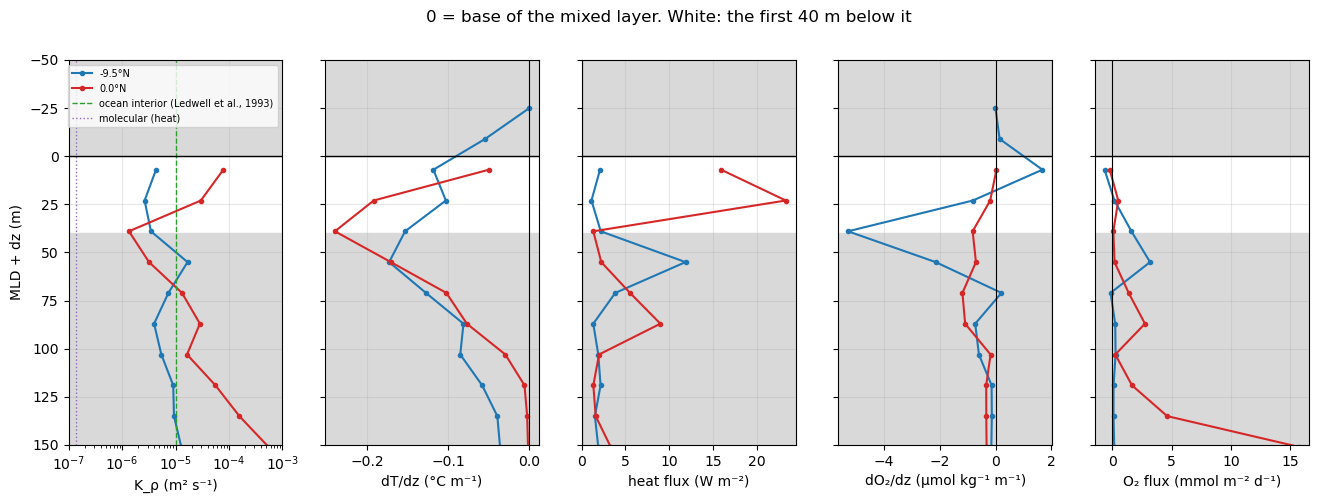

In [159]:
# K, gradients and fluxes against the depth below the mixed layer; white: the first 40 m below it
fig, axs = plt.subplots(1, 5, figsize=(16, 5), sharey=True)
for s, c in stations.items():
    dz = zm - col[s]["mld"]                          # depth below the mixed layer
    lab = f"{col[s]['lat']:.1f}°N"
    axs[0].semilogx(K[s], dz, "o-", ms=3, color=c, label=lab)
    axs[1].plot(dTdz[s], dz, "o-", ms=3, color=c)
    axs[2].plot(F_heat[s], dz, "o-", ms=3, color=c)
    axs[3].plot(dOdz[s], dz, "o-", ms=3, color=c)
    axs[4].plot(F_O2[s], dz, "o-", ms=3, color=c)
axs[0].axvline(1e-5, color="tab:green", ls="--", lw=1, label="ocean interior (Ledwell et al., 1993)")
axs[0].axvline(1.4e-7, color="tab:purple", ls=":", lw=1, label="molecular (heat)")
labels = ["K_ρ (m² s⁻¹)", "dT/dz (°C m⁻¹)", "heat flux (W m⁻²)", "dO₂/dz (µmol kg⁻¹ m⁻¹)", "O₂ flux (mmol m⁻² d⁻¹)"]
for ax, label in zip(axs, labels):
    ax.axhspan(-50, 0, color="0.85")            # mixed layer
    ax.axhspan(40, 150, color="0.85")           # deeper than 40 m below the mixed layer
    ax.axhline(0, color="k", lw=1)
    ax.set_xlabel(label); ax.grid(alpha=0.3)
for ax in axs[1:]:
    ax.axvline(0, color="k", lw=0.8)
axs[0].set_xlim(1e-7, 1e-3)
axs[0].set_ylim(150, -50); axs[0].set_ylabel("MLD + dz (m)"); axs[0].legend(fontsize=7)
fig.suptitle("0 = base of the mixed layer. White: the first 40 m below it");

**✏️ Your turn.** As in step 3, compute the median of $K_\rho$, of the heat flux and of the oxygen flux in the two layers at each station:

- **below**: the first 40 m below the mixed layer;
- **deeper**: from 40 to 150 m below the mixed layer.

In [160]:
# Median of K, heat flux and oxygen flux, 0-40 m and 40-150 m below the mixed layer
for s in stations:
    mld = col[s]["mld"]
    below = (zm > mld) & (zm <= mld + 40)           # 0 to 40 m below the mixed layer
    deeper = (zm > mld + 40) & (zm <= mld + 150)    # 40 to 150 m below the mixed layer

    print(col[s]["lat"], "°N")
    print("  below : K      =", f"{np.nanmedian(K[s][below]):.1e}")
    print("          F_heat =", f"{np.nanmedian(F_heat[s][below]):.1e}")
    print("          F_O2   =", f"{np.nanmedian(F_O2[s][below]):.1e}")
    print("  deeper: K      =", f"{np.nanmedian(K[s][deeper]):.1e}")
    print("          F_heat =", f"{np.nanmedian(F_heat[s][deeper]):.1e}")
    print("          F_O2   =", f"{np.nanmedian(F_O2[s][deeper]):.1e}")

-9.5 °N
  below : K      = 3.5e-06
          F_heat = 2.1e+00
          F_O2   = 1.9e-01
  deeper: K      = 8.2e-06
          F_heat = 2.0e+00
          F_O2   = 1.9e-01
0.0 °N
  below : K      = 3.0e-05
          F_heat = 1.6e+01
          F_O2   = 9.8e-02
  deeper: K      = 2.2e-05
          F_heat = 2.1e+00
          F_O2   = 1.5e+00


::::{note} Questions
**4.1** Compare $K_\rho$ at the two stations with the molecular diffusivity of heat ($1.4 \times 10^{-7}$ m² s⁻¹) and with the value of the ocean interior ($10^{-5}$ m² s⁻¹, Ledwell et al., 1993).

**4.2** Just below the mixed layer, which station removes more heat from the surface layer, and why? Hummels et al. (2013) found heat fluxes below the mixed layer generally below 10 W m⁻² off the equator, and of several tens of W m⁻² at the equator in boreal summer. Where do our March values stand ({numref}`fig-moum`)?

**4.3** Compare the oxygen flux at the two stations, in the two layers. Is it always larger where $K_\rho$ is larger? Which factor makes the difference?

:::{dropdown} Answers
**4.1**
- At 9.5°S, $K_\rho$ is a few $10^{-6}$ m² s⁻¹: 25 to 60 times the molecular diffusivity, but below the value of the ocean interior.
- At the equator, $K_\rho$ is 2–3 $\times 10^{-5}$ m² s⁻¹: above the value of the ocean interior, and about 9 times more than at 9.5°S just below the mixed layer.

**4.2**
- Just below the mixed layer, the heat flux is about 16 W m⁻² at the equator, against 2 W m⁻² at 9.5°S: **8 times more**. The temperature gradient is similar; the difference comes from $K_\rho$, that is from the shear-driven turbulence of step 3.
- Off the equator, 2 W m⁻² agrees with Hummels et al. (2013). At the equator, 16 W m⁻² is well below their summer values: in March, heating by the sun wins and turbulence cools the surface little ({numref}`fig-moum`).
- Deeper, the heat flux is about 2 W m⁻² at both stations.

**4.3**
- Just below the mixed layer, the oxygen flux is smaller at the equator (0.1 against 0.2 mmol m⁻² d⁻¹), although $K_\rho$ is 9 times larger: oxygen hardly changes with depth there (step 1).
- Deeper, where oxygen decreases with depth at the equator, the flux is about 8 times larger than at 9.5°S (1.5 against 0.2 mmol m⁻² d⁻¹). This layer includes weakly stratified water, where $K_\rho$ is less certain: take this value as an order of magnitude.
:::
::::

## Going further: the whole section

Our conclusions rest on two profiles. Are they representative? The cell below computes, for the 24 stations of the section, the median of $\varepsilon$ in the first 40 m below the mixed layer.

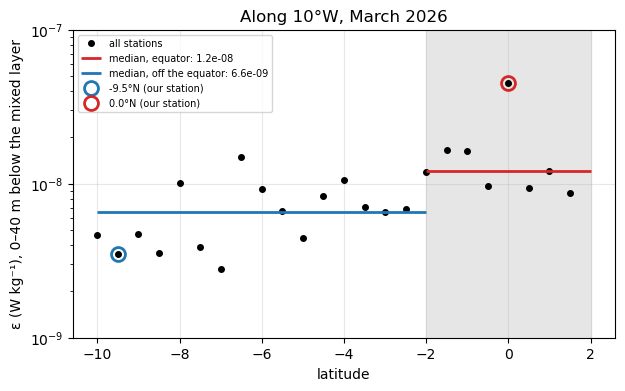

In [165]:
# Median eps in the first 40 m below the mixed layer, at the 24 stations of the section
lat_all, eps_all = [], []
for s in prof.station.values:
    p = prof.sel(station=s)
    mld = float(p.mld)
    below = (pres > mld) & (pres <= mld + 40)
    lat_all.append(float(p.lat))
    eps_all.append(np.nanmedian(p.eps.values[below]))
lat_all, eps_all = np.array(lat_all), np.array(eps_all)

# Median of each zone: equator (2°S-2°N) and off the equator (south of 2°S)
eq = np.abs(lat_all) <= 2
off = lat_all < -2
med_eq, med_off = np.nanmedian(eps_all[eq]), np.nanmedian(eps_all[off])

fig, ax = plt.subplots(figsize=(7, 4))
ax.axvspan(-2, 2, color="0.9")
ax.semilogy(lat_all, eps_all, "ko", ms=4, label="all stations")
ax.hlines(med_eq, -2, 2, color="tab:red", lw=2, label=f"median, equator: {med_eq:.1e}")
ax.hlines(med_off, lat_all[off].min(), -2, color="tab:blue", lw=2, label=f"median, off the equator: {med_off:.1e}")
for s, c in stations.items():
    i = list(prof.station.values).index(s)
    ax.semilogy(lat_all[i], eps_all[i], "o", ms=10, mfc="none", mew=2, color=c, label=f"{col[s]['lat']:.1f}°N (our station)")
ax.set_xlabel("latitude"); ax.set_ylabel("ε (W kg⁻¹), 0–40 m below the mixed layer")
ax.grid(alpha=0.3); ax.legend(fontsize=7)
ax.set_ylim(1e-9, 1e-7)
ax.set_title("Along 10°W, March 2026");

In [166]:
print(f"Median eps below the mixed layer: {med_eq / med_off:.0f} times larger at the equator than off the equator")

Median eps below the mixed layer: 2 times larger at the equator than off the equator


:::{tip} Take-home
- **$\varepsilon$ can be trusted**: the two probes agree within a factor of 2 for most segments, and the spectra follow the model above the noise.
- **Just below the mixed layer, the equator is more turbulent**, although it is more stratified: the shear of the Equatorial Undercurrent feeds the turbulence (Hummels et al., 2013).
- **At the equator, this turbulence removes about 8 times more heat from the surface layer**, but it moves oxygen only where there is an oxygen gradient: a flux is $K_\rho$ times a gradient.
- **Two contrasted stations, one season**: we chose two contrasted cases for this exercise (about 16 times more turbulence at the equator). Along the whole section, the equator is still about 2 times more turbulent on average.
:::